In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [2]:
import sklearn
sklearn.__version__

'1.9.1'

# Кодирование переменных

## Ordinal Encoder

**Применяется для признаков!** Работает с матрицами

In [3]:
from sklearn.preprocessing import OrdinalEncoder
enc = OrdinalEncoder()
X = [['Male', 1], ['Female', 3], ['Female', 2],['Gender',1],['Gender',10],['Gender',3]]
enc.fit(X)
enc.categories_

[array(['Female', 'Gender', 'Male'], dtype=object),
 array([1, 2, 3, 10], dtype=object)]

In [4]:
enc.transform([['Female', 3], ['Male', 1],['Gender',10]])

array([[0., 2.],
       [2., 0.],
       [1., 3.]])

In [5]:
enc.categories_

[array(['Female', 'Gender', 'Male'], dtype=object),
 array([1, 2, 3, 10], dtype=object)]

In [6]:
enc.inverse_transform([[1, 0], [0, 3]])

array([['Gender', 1],
       ['Female', 10]], dtype=object)

## LabelEncoder

**Применяется для целевых переменных!** Работает с вектором, не рекомендуется *производителем* использование с признаками.

In [7]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit([1, 2, 2, 6])
le.classes_

array([1, 2, 6])

In [8]:
le.transform([1, 1, 2, 6])

array([0, 0, 1, 2])

In [9]:
le.inverse_transform([0, 0, 1, 2])

array([1, 1, 2, 6])

In [11]:
le = LabelEncoder()
le.fit(["paris", "paris", "tokyo", "amsterdam"])
le.classes_

array(['amsterdam', 'paris', 'tokyo'], dtype='<U9')

In [12]:
le.transform(["tokyo", "tokyo", "paris"])

array([2, 2, 1])

In [13]:
le.inverse_transform([2, 2, 1])

array(['tokyo', 'tokyo', 'paris'], dtype='<U9')

## OneHotEncoder

**Dummies.**  Кодирует по отдельности каждый столбец через 0 и 1

In [14]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(handle_unknown='ignore') # позволяет игнорировать при будущей кодировки неизвестные на train варианты
X = [['Male', 1], ['Female', 3], ['Female', 2]]
enc.fit(X)
enc.categories_

[array(['Female', 'Male'], dtype=object), array([1, 2, 3], dtype=object)]

In [15]:
# handle_unknown='ignore' ВНИМАНИЕ неивестные обращаются в 0-вектор
enc.transform([['Female', 1], ['Male', 10]]).toarray()

array([[1., 0., 1., 0., 0.],
       [0., 1., 0., 0., 0.]])

In [16]:
enc.inverse_transform([[0, 1, 1, 0, 0], [0, 0, 0, 1, 0]])

array([['Male', 1],
       [None, 2]], dtype=object)

In [17]:
enc.get_feature_names_out(['gender', 'group'])

array(['gender_Female', 'gender_Male', 'group_1', 'group_2', 'group_3'],
      dtype=object)

In [18]:
drop_enc = OneHotEncoder(drop='first').fit(X)
drop_enc.categories_

[array(['Female', 'Male'], dtype=object), array([1, 2, 3], dtype=object)]

In [19]:
drop_enc.transform([['Female', 1], ['Male', 2]]).toarray()

array([[0., 0., 0.],
       [1., 1., 0.]])

In [20]:
# если переменных только две кодировать в один столбик
drop_binary_enc = OneHotEncoder(drop='if_binary').fit(X)
drop_binary_enc.transform([['Female', 1], ['Male', 2],['Female', 1]]).toarray()

array([[0., 1., 0., 0.],
       [1., 0., 1., 0.],
       [0., 1., 0., 0.]])

In [22]:
# кодировать прорущенную переменную не как np.nan
enc = OrdinalEncoder(encoded_missing_value=-1)
X = [['male'], ['female'], [np.nan], ['female']]
enc.fit_transform(X)

array([[ 1.],
       [ 0.],
       [-1.],
       [ 0.]])

## Приведение переменных к "удобному" виду

Цель сделать так, чтобы столбец данных имел более "приятное распределение для вычислений". Используется как для целевой переменной, так и для признаков.

### `QuantileTransformer`

Приведение к равномерному или нормальному распределению (численный алгоритм). Работает поквантильно.

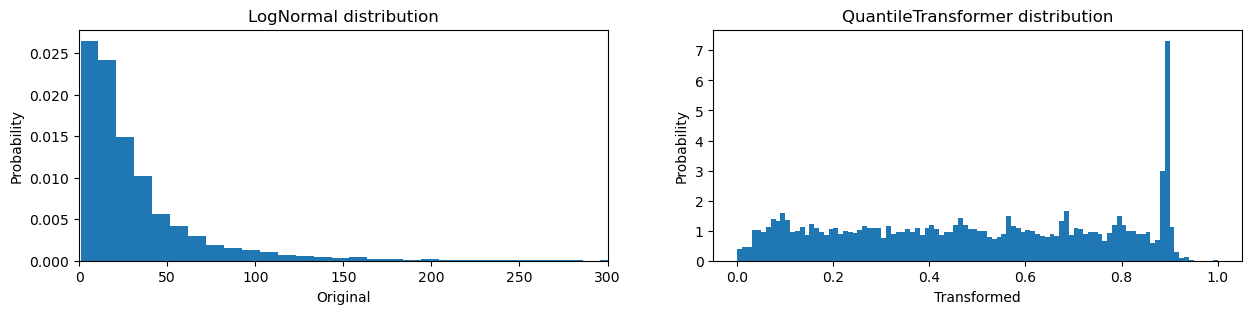

In [23]:
from sklearn.preprocessing import QuantileTransformer

mu, sigma = 3., 1.
np.random.seed(42)
x = np.random.lognormal(mu, sigma, 5000).reshape(-1, 1)
x_qt = QuantileTransformer(n_quantiles=10, random_state=42).fit_transform(x)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(15,3))
ax0.hist(x, bins=100, density=True)
ax0.set_xlim([0, 300])
ax0.set_ylabel("Probability")
ax0.set_xlabel("Original")
ax0.set_title("LogNormal distribution")
ax1.hist(x_qt, bins=100, density=True)
ax1.set_ylabel("Probability")
ax1.set_xlabel("Transformed")
ax1.set_title("QuantileTransformer distribution");

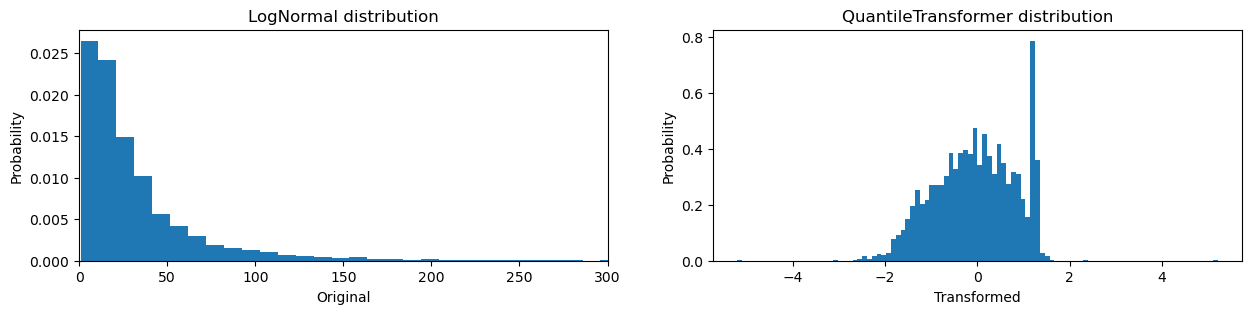

In [24]:
x_qt = QuantileTransformer(n_quantiles=10, output_distribution = 'normal', random_state=42).fit_transform(x)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(15,3))
ax0.hist(x, bins=100, density=True)
ax0.set_xlim([0, 300])
ax0.set_ylabel("Probability")
ax0.set_xlabel("Original")
ax0.set_title("LogNormal distribution")
ax1.hist(x_qt, bins=100, density=True)
ax1.set_ylabel("Probability")
ax1.set_xlabel("Transformed")
ax1.set_title("QuantileTransformer distribution");

### `PowerTransformer`

Преобразование Бокса-Кокса (только для положительных) и преобразование Йео-Джонсона (для любых)

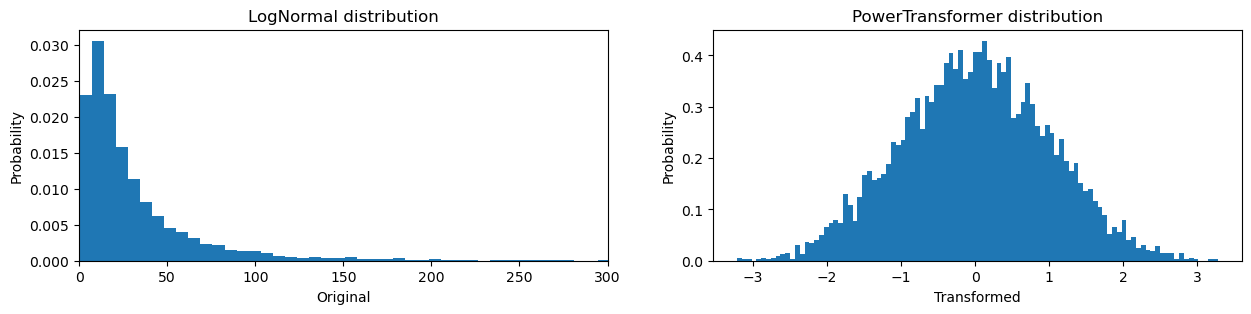

In [25]:
from sklearn.preprocessing import PowerTransformer

x = np.random.lognormal(mu, sigma, 5000).reshape(-1, 1)
x_pt = PowerTransformer().fit_transform(x)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(15,3))
ax0.hist(x, bins=100, density=True)
ax0.set_xlim([0, 300])
ax0.set_ylabel("Probability")
ax0.set_xlabel("Original")
ax0.set_title("LogNormal distribution")
ax1.hist(x_pt, bins=100, density=True)
ax1.set_ylabel("Probability")
ax1.set_xlabel("Transformed")
ax1.set_title("PowerTransformer distribution");

## `TargetEncoder`

Метод преобразования категориальных признаков в числовые, при котором каждую категорию заменяют средним значением целевой переменной для этой категории.

- обучающая выборка делится на фолды, статистика для каждого фолда считается на валидационном фолде
- используется сглаживание, для предотвращения переобучения под выбросы

In [26]:
from sklearn.preprocessing import TargetEncoder

X = np.array([["dog"] * 20 + ["cat"] * 30 + ["snake"] * 38], dtype=object).T
y = [90.3] * 5 + [80.1] * 15 + [20.4] * 5 + [20.1] * 25 + [21.2] * 8 + [49] * 30
display(pd.DataFrame({"X":X.reshape(-1), 'y':y}).head(3))
display(pd.DataFrame({"X":X.reshape(-1), 'y':y}).tail(3))

,X,y
0,dog,90.3
1,dog,90.3
2,dog,90.3


,X,y
85,snake,49.0
86,snake,49.0
87,snake,49.0


In [27]:
X_te = TargetEncoder(smooth="auto").fit_transform(X, y)

In [28]:
display(pd.DataFrame({"X":X_te.reshape(-1), 'y':y}).head(3))
display(pd.DataFrame({"X":X_te.reshape(-1), 'y':y}).tail(3))

,X,y
0,81.844781,90.3
1,81.947604,90.3
2,82.571809,90.3


,X,y
85,42.524796,49.0
86,43.451657,49.0
87,43.451657,49.0


## Что есть еще

1. [`Binarizer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.Binarizer.html#sklearn.preprocessing.Binarizer) - кодирует по порогу в 0 или 1 - поговорим на отборе признаков
2. [`SplineTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html) - поговорим при  обработке временных рядов, позволяет "сшивать" данные.
3. [`FunctionTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.FunctionTransformer.html) - собственные преобразования с использоанием своих функций, тоже поговорим при обработке временных данных.

# Заполнение пропусков

## Заполнение средним или наиболее частым

In [51]:
from sklearn.impute import SimpleImputer

X = [[np.nan, 2], [6, np.nan], [7, 6]]
imp = SimpleImputer(missing_values=np.nan, strategy='mean')
imp.fit(X)

display(pd.DataFrame(X))
display(pd.DataFrame(imp.transform(X)))

,0,1
0,NaN,2.0
1,6.0,NaN
2,7.0,6.0


,0,1
0,6.5,2.0
1,6.0,4.0
2,7.0,6.0


In [52]:
X = [[np.nan, 'dog'], ['red', np.nan], ['green', 'dog'], ['red','cat']]
imp = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
imp.fit(X)

display(pd.DataFrame(X))
display(pd.DataFrame(imp.transform(X)))

,0,1
0,NaN,dog
1,red,NaN
2,green,dog
3,red,cat


,0,1
0,red,dog
1,red,dog
2,green,dog
3,red,cat


### `IterativeImputer`

Итеративный подхлд - моделирует каждый объект с пропущенными значениями в зависимости от других объектов и использует эту оценку для условного вычисления пропущенного значения. Это происходит циклически: на каждом шаге столбец признаков с пропусками обозначается как целевой, а другие столбцы признаков обрабатываются как фичи.

In [53]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


X = [[np.nan, 2], [6, np.nan], [7, 6]]
imp = IterativeImputer(missing_values=np.nan)
imp.fit(X)

display(pd.DataFrame(X))
display(pd.DataFrame(imp.transform(X)))

,0,1
0,NaN,2.0
1,6.0,NaN
2,7.0,6.0


,0,1
0,5.000012,2.000000
1,6.000000,3.999988
2,7.000000,6.000000


### `KNNImputer`

Метод ближайших соседей

In [54]:
from sklearn.impute import KNNImputer
X = [[np.nan, 2], [6, np.nan], [7, 6]]
imp = KNNImputer(missing_values=np.nan)
imp.fit(X)

display(pd.DataFrame(X))
display(pd.DataFrame(imp.transform(X)))

,0,1
0,NaN,2.0
1,6.0,NaN
2,7.0,6.0


,0,1
0,7.0,2.0
1,6.0,6.0
2,7.0,6.0
